# Análisis no supervisado: perfiles exploratorios de arbolado

Complemento de la entrega 4: se agrupan árboles por características físicas y contexto para describir patrones del arbolado. Los grupos no son etiquetas de daño ni de riesgo y no deben usarse para decidir inspecciones sin validación. Se excluyen `sidewalk` y `target` del clustering.

In [1]:
from pathlib import Path
import sys
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
ROOT = Path.cwd()
if not (ROOT/'data').exists() and (ROOT/'Final'/'data').exists(): ROOT = ROOT/'Final'
if not (ROOT/'data').exists() and (ROOT.parent/'Final'/'data').exists(): ROOT = ROOT.parent/'Final'
sys.path.insert(0, str(ROOT))
DATA = ROOT/'data'/'nyc_tree_census_sample.csv'
if not DATA.exists(): raise FileNotFoundError('Ejecutar antes: python download_dataset.py')
df = pd.read_csv(DATA, low_memory=False)
print('Filas y columnas:', df.shape)
display(df.head())

Filas y columnas: (100000, 20)


,tree_id,tree_dbh,curb_loc,boroname,status,health,spc_latin,steward,guards,sidewalk,problems,root_stone,root_grate,root_other,trunk_wire,trnk_light,trnk_other,brch_light,brch_shoe,brch_other
0,3,24,OnCurb,Bronx,Alive,Good,Quercus palustris,1or2,NaN,Damage,NaN,No,No,No,No,No,No,No,No,No
1,592148,11,OnCurb,Queens,Alive,Good,Acer platanoides,NaN,NaN,NoDamage,NaN,No,No,No,No,No,No,No,No,No
2,7,3,OnCurb,Bronx,Alive,Poor,Betula pendula,3or4,NaN,NoDamage,NaN,No,No,No,No,No,No,No,No,No
3,625082,4,OnCurb,Brooklyn,Alive,Good,Quercus acutissima,NaN,NaN,NoDamage,NaN,No,No,No,No,No,No,No,No,No
4,562916,9,OnCurb,Queens,Alive,Good,Prunus,NaN,NaN,NoDamage,NaN,No,No,No,No,No,No,No,No,No


## Ingeniería de variables y submuestra
Se calculan conteos de conflictos de raíz/tronco/ramas y se eligen variables para clustering. Para que el costo sea razonable se utiliza una muestra reproducible. Las categorías se codifican dentro del preprocesador; las numéricas se estandarizan porque K-Means usa distancias.

In [2]:
from model import engineer_features
prepared = engineer_features(df)
prepared = prepared[prepared.tree_dbh.between(1,60)].copy()
sample = prepared.sample(min(10000,len(prepared)), random_state=42)
num = ['tree_dbh','root_conflict_score','trunk_conflict_score','branch_conflict_score']
cat = ['borough','health','curb_loc','spc_clean']
X_raw = sample[num+cat]
print('Filas usadas:', len(sample), 'daño excluido como variable:', 'target' not in X_raw)

Filas usadas: 10000 daño excluido como variable: True


In [3]:
prep = ColumnTransformer([
 ('num', Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())]), num),
 ('cat', Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('ohe',OneHotEncoder(handle_unknown='ignore',min_frequency=10))]), cat)])
X = prep.fit_transform(X_raw)
if hasattr(X,'toarray'): X = X.toarray()
X.shape

(10000, 35)

## Selección exploratoria de k: codo y silhouette
La inercia siempre disminuye al aumentar k; el codo es una heurística. Silhouette mide cohesión/separación geométrica, no impacto ni utilidad social. Por la codificación one-hot, los grupos pueden reflejar estructura de categorías.

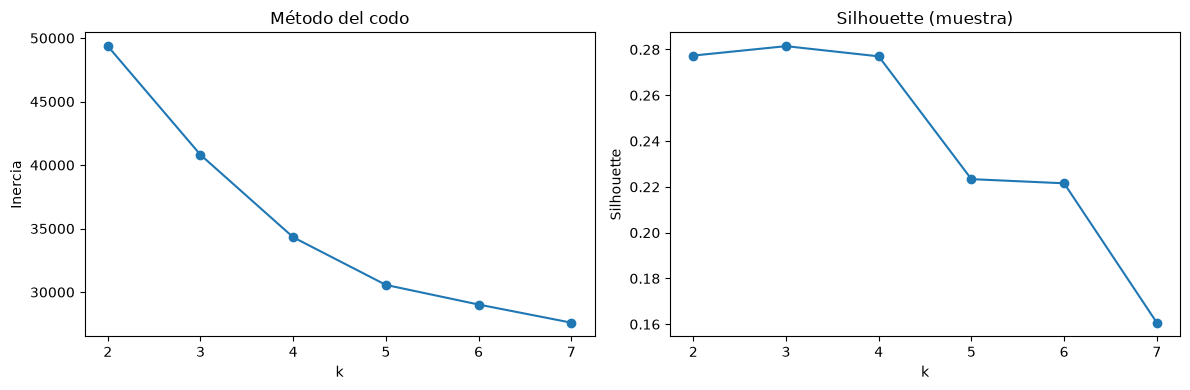

{2: np.float64(0.2774), 3: np.float64(0.2815), 4: np.float64(0.277), 5: np.float64(0.2234), 6: np.float64(0.2216), 7: np.float64(0.1607)}


In [4]:
ks = range(2,8)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_, sample_size=min(3000,len(sample)), random_state=42))
fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(list(ks),inertias,marker='o'); ax[0].set(title='Método del codo',xlabel='k',ylabel='Inercia')
ax[1].plot(list(ks),silhouettes,marker='o'); ax[1].set(title='Silhouette (muestra)',xlabel='k',ylabel='Silhouette')
plt.tight_layout(); plt.show()
print(dict(zip(ks,np.round(silhouettes,4))))

In [5]:
best_k = list(ks)[int(np.argmax(silhouettes))]
km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
sample['cluster'] = km.fit_predict(X)
summary = sample.groupby('cluster').agg(
    cantidad=('tree_dbh','size'), diametro_mediano=('tree_dbh','median'),
    conflicto_raiz_mediano=('root_conflict_score','median'),
    conflicto_raiz_promedio=('root_conflict_score','mean'),
    salud_moda=('health',lambda x:x.mode().iloc[0] if not x.mode().empty else 'Unknown')
).round(2)
display(summary)

,cantidad,diametro_mediano,conflicto_raiz_mediano,conflicto_raiz_promedio,salud_moda
cluster,,,,,
0,670,11.0,0.0,0.55,Good
1,7004,8.0,0.0,0.00,Good
2,2326,16.0,1.0,0.99,Good


## Contraste con DBSCAN (opcional / exploratorio)
DBSCAN identifica componentes densos y ruido, pero el espacio one-hot es de alta dimensión; una métrica silhouette puede no ser informativa. Se ejecuta sobre una submuestra pequeña y no se fuerza un resultado positivo. Interpretar número de clusters y fracción de ruido.

In [6]:
small_n = min(3000, len(sample))
labels = DBSCAN(eps=2.5, min_samples=20, n_jobs=-1).fit_predict(X[:small_n])
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
noise_rate = float(np.mean(labels == -1))
print({'clusters_sin_ruido': n_clusters, 'proporcion_ruido': round(noise_rate,3)})
if n_clusters >= 2 and np.sum(labels != -1) > n_clusters:
    mask = labels != -1
    print('silhouette_no_ruido:', round(silhouette_score(X[:small_n][mask], labels[mask], sample_size=min(1500,mask.sum()), random_state=42),4))
else:
    print('No se calcula silhouette: DBSCAN no produjo al menos dos clusters no-ruido suficientes.')

{'clusters_sin_ruido': 5, 'proporcion_ruido': 0.012}
silhouette_no_ruido: 0.3333


## Resultados y conclusiones exploratorias
En esta corrida sobre 10.000 árboles, silhouette fue máximo para k=3 (0,2815; k=2: 0,2774), una separación geométrica modesta. K-Means produjo grupos de 670, 7.004 y 2.326 árboles. Sus medianas de diámetro fueron 11, 8 y 16 pulgadas, y las medianas del conteo de conflictos de raíz 0, 0 y 1; salud modal Good en los tres grupos. DBSCAN (eps=2,5; min_samples=20) encontró 5 grupos y marcó 1,2% como ruido; silhouette en los puntos no-ruido fue 0,3333. No se afirma que esos grupos sean perfiles naturales o de riesgo: dependen de la muestra, variables, escalado, OneHotEncoder y parámetros, y el espacio categórico de alta dimensión limita la interpretación. El clustering es exploratorio, no causal y no reemplaza inspecciones.